### Week 4 - Project 1
### Yana Rabkova

Introduction

This project explores the structure of the U.S. domestic airport network using January 2025 flight data from the Bureau of Transportation Statistics (BTS).

Each airport is represented as a node, and a direct flight connection between two airports is represented as an undirected edge. The network is unweighted, meaning that each unique airport pair is counted once regardless of flight frequency.

The primary objective is to calculate degree centrality and eigenvector centrality for each airport and compare these measures across airport-size categories, defined using departing flight volume.

I also explore whether airports with similar numbers of connections necessarily occupy similarly influential positions within the network.

In [1]:
#loading libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy import stats


#loading data
df = pd.read_csv("T_ONTIME_REPORTING.csv")
df.head()

,FL_DATE,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_STATE_ABR,DEP_DELAY,DEP_DEL15,CANCELLED,DIVERTED,FLIGHTS
0,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,11057,CLT,NC,-10.0,0.0,0.0,0.0,1.0
1,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,11057,CLT,NC,-8.0,0.0,0.0,0.0,1.0
2,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,11057,CLT,NC,-4.0,0.0,0.0,0.0,1.0
3,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,14082,PGD,FL,-10.0,0.0,0.0,0.0,1.0
4,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,14112,PIE,FL,-4.0,0.0,0.0,0.0,1.0


In [2]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names and data types
df.info()

# Preview the first 5 rows
display(df.head())

Dataset shape: (539747, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539747 entries, 0 to 539746
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   FL_DATE            539747 non-null  object 
 1   ORIGIN_AIRPORT_ID  539747 non-null  int64  
 2   ORIGIN             539747 non-null  object 
 3   ORIGIN_CITY_NAME   539747 non-null  object 
 4   ORIGIN_STATE_ABR   539747 non-null  object 
 5   DEST_AIRPORT_ID    539747 non-null  int64  
 6   DEST               539747 non-null  object 
 7   DEST_STATE_ABR     539747 non-null  object 
 8   DEP_DELAY          523824 non-null  float64
 9   DEP_DEL15          523824 non-null  float64
 10  CANCELLED          539747 non-null  float64
 11  DIVERTED           539747 non-null  float64
 12  FLIGHTS            539747 non-null  float64
dtypes: float64(5), int64(2), object(6)
memory usage: 53.5+ MB


,FL_DATE,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_STATE_ABR,DEP_DELAY,DEP_DEL15,CANCELLED,DIVERTED,FLIGHTS
0,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,11057,CLT,NC,-10.0,0.0,0.0,0.0,1.0
1,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,11057,CLT,NC,-8.0,0.0,0.0,0.0,1.0
2,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,11057,CLT,NC,-4.0,0.0,0.0,0.0,1.0
3,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,14082,PGD,FL,-10.0,0.0,0.0,0.0,1.0
4,1/1/2025 12:00:00 AM,10135,ABE,"Allentown/Bethlehem/Easton, PA",PA,14112,PIE,FL,-4.0,0.0,0.0,0.0,1.0


The dataset contains 539,747 flight records from January 2025 and 13 variables, including origin and destination airports, departure delays, cancellations, and diversions.

For this project, the most important variables are the origin and destination airports, which will be used to construct the network. The remaining variables provide additional information about flight activity and may be useful for future analysis.

In [3]:
# Missing values
missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": df.isna().mean() * 100
})

display(missing.sort_values("Missing_Percent", ascending=False))

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

,Missing_Count,Missing_Percent
DEP_DELAY,15923,2.950086
DEP_DEL15,15923,2.950086
FL_DATE,0,0.000000
ORIGIN_AIRPORT_ID,0,0.000000
ORIGIN,0,0.000000
ORIGIN_CITY_NAME,0,0.000000
ORIGIN_STATE_ABR,0,0.000000
DEST_AIRPORT_ID,0,0.000000
DEST,0,0.000000
DEST_STATE_ABR,0,0.000000


Duplicate rows: 68950


In [4]:
pd.crosstab(
    df["DEP_DELAY"].isna(),
    df["CANCELLED"]
)

CANCELLED,0.0,1.0
DEP_DELAY,,
False,523435,389
True,0,15923


The missing-value analysis showed that 15,923 records have missing departure-delay information, and all of these records correspond to canceled flights.

Since the current analysis focuses on airport connections rather than flight delays, I decided to retain these records when constructing the network. This allows the network to represent the routes reported in the dataset, including scheduled flights that were canceled.

In [5]:
# Unique airports (nodes)
airports = set(df["ORIGIN"]) | set(df["DEST"])

print("Number of airports:", len(airports))

# Unique directed routes
directed_routes = df[["ORIGIN", "DEST"]].drop_duplicates()

print("Number of directed routes:", len(directed_routes))

# Unique undirected routes
routes = df[["ORIGIN", "DEST"]].copy()

routes["airport_1"] = routes[["ORIGIN", "DEST"]].min(axis=1)
routes["airport_2"] = routes[["ORIGIN", "DEST"]].max(axis=1)

undirected_routes = routes[
    ["airport_1", "airport_2"]
].drop_duplicates()

print("Number of undirected routes:", len(undirected_routes))

Number of airports: 329
Number of directed routes: 5649
Number of undirected routes: 2829


The dataset includes 329 unique airports and 5,649 directed routes. When treating connections as undirected, the number of unique routes decreases to 2,829.

I decided to use an undirected network because the primary objective is to understand which airports are connected, rather than the direction of individual flights. Each connection is counted once, regardless of how many flights occurred between the two airports.

## Network Construction and Descriptive Statistics

In [34]:
import networkx as nx

G = nx.from_pandas_edgelist(
    undirected_routes,
    source="airport_1",
    target="airport_2"
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Network density:", round(nx.density(G), 4))
print("Connected components:", nx.number_connected_components(G))
print("Average degree:", round(
    sum(dict(G.degree()).values()) / G.number_of_nodes(), 2
))

degree_df["Degree"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

Nodes: 329
Edges: 2829
Network density: 0.0524
Connected components: 1
Average degree: 17.2


count    329.000000
mean      17.197568
std       27.655115
min        1.000000
25%        2.000000
50%        6.000000
75%       19.000000
90%       55.200000
95%       82.600000
99%      132.640000
max      177.000000
Name: Degree, dtype: float64

To construct the airport network, I used NetworkX, representing each airport as a node and each unique connection between two airports as an edge. The network is undirected and unweighted, meaning that flight direction and frequency are not considered.

The resulting network contains 329 airports and 2,829 connections. The network consists of a single connected component, meaning that all 329 airports are connected through at least one path, although not necessarily through direct flights.

The network density is approximately 0.052, indicating that only about 5.2% of all possible airport pairs have a direct connection. The average degree is 17.2, while the median is only 6, suggesting that connectivity is unevenly distributed across airports.

The maximum degree is 177, indicating that the most connected airport has direct routes to 177 other airports.


In [7]:
degree_df = pd.DataFrame(
    G.degree(),
    columns=["Airport", "Degree"]
)

display(
    degree_df.sort_values(
        "Degree", ascending=False
    ).head(15)
)

,Airport,Degree
6,DFW,177
13,DEN,165
21,ORD,145
8,ATL,136
16,LAS,124
1,CLT,120
22,PHX,107
20,MSP,101
41,DCA,93
15,IAH,88


The airports with the highest number of direct connections include Dallas/Fort Worth (DFW), Denver (DEN), Chicago O'Hare (ORD), and Atlanta (ATL). DFW has the highest degree, with 177 connections, followed by DEN with 165.

These airports appear to function as major hubs within the network, connecting a large number of destinations.

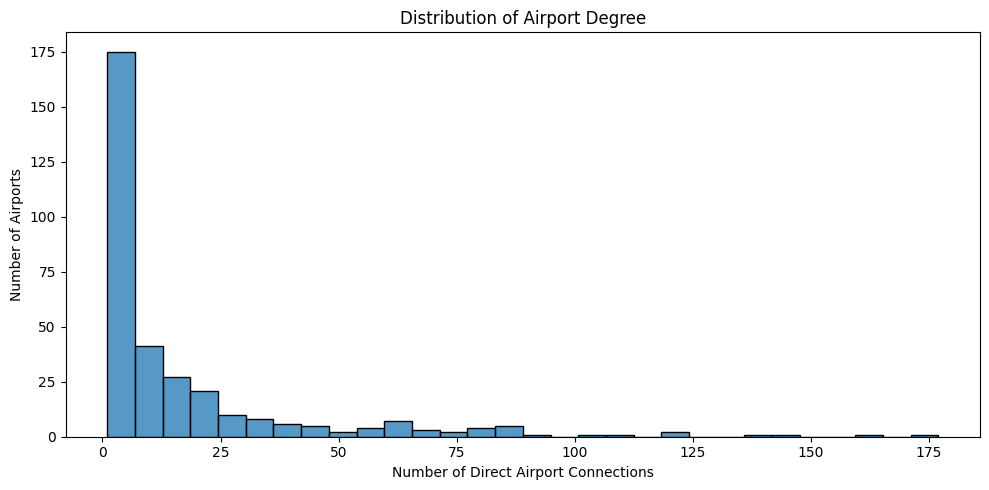

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=degree_df,
    x="Degree",
    bins=30
)

plt.title("Distribution of Airport Degree")
plt.xlabel("Number of Direct Airport Connections")
plt.ylabel("Number of Airports")
plt.tight_layout()
plt.show()

In [10]:
# Degree centrality
degree_centrality = nx.degree_centrality(G)

# Eigenvector centrality
eigenvector_centrality = nx.eigenvector_centrality(
    G,
    max_iter=1000,
    tol=1e-6
)

# Create airport-level dataframe
centrality_df = pd.DataFrame({
    "Airport": list(G.nodes()),
    "Degree": [G.degree(n) for n in G.nodes()],
    "Degree_Centrality": [
        degree_centrality[n] for n in G.nodes()
    ],
    "Eigenvector_Centrality": [
        eigenvector_centrality[n] for n in G.nodes()
    ]
})

display(
    centrality_df.sort_values(
        "Eigenvector_Centrality",
        ascending=False
    ).head(15)
)

,Airport,Degree,Degree_Centrality,Eigenvector_Centrality
6,DFW,177,0.539634,0.189801
13,DEN,165,0.503049,0.187838
8,ATL,136,0.414634,0.184084
21,ORD,145,0.442073,0.179358
1,CLT,120,0.365854,0.168084
16,LAS,124,0.378049,0.165581
22,PHX,107,0.326220,0.158905
20,MSP,101,0.307927,0.150772
52,BNA,83,0.253049,0.149434
41,DCA,93,0.283537,0.147608


The results show that major airports such as DFW, DEN, ATL, and ORD have the highest eigenvector centrality scores, suggesting that they are not only well connected but also connected to other influential airports.

Although degree and eigenvector centrality generally follow similar patterns, their rankings are not identical. For example, ATL has fewer direct connections than ORD but a slightly higher eigenvector centrality score. This suggests that the number of connections alone does not fully capture an airport's importance within the network.

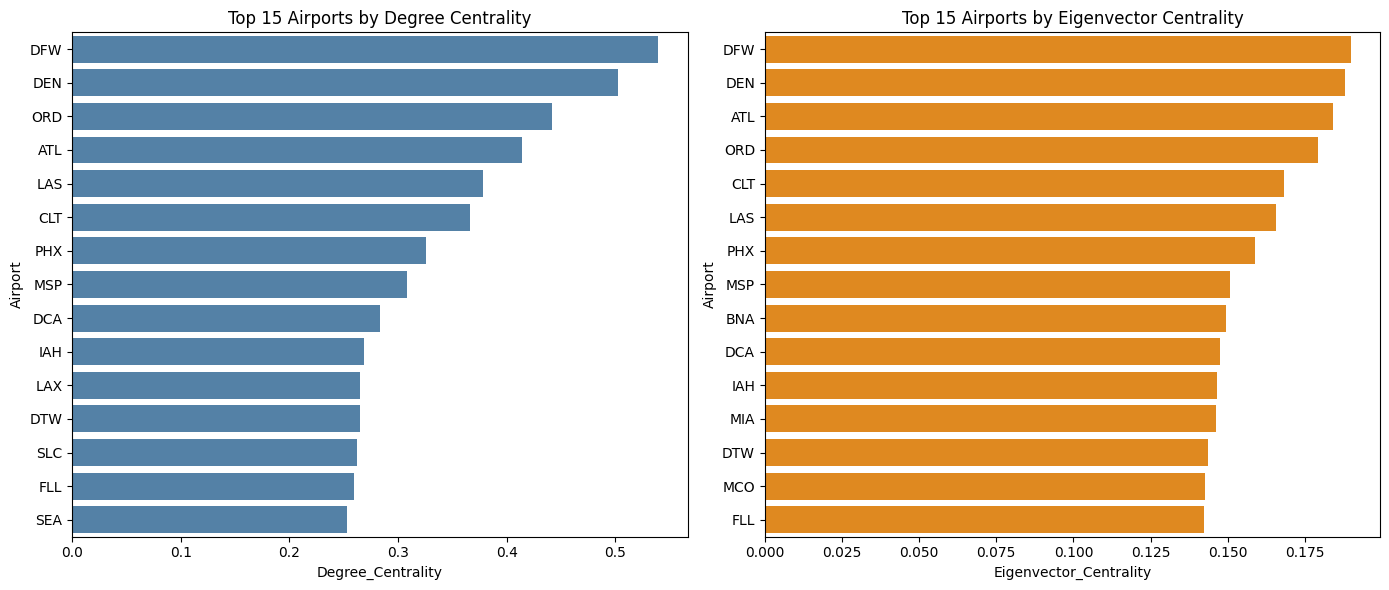

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_degree = centrality_df.nlargest(15, "Degree_Centrality")
top_eigen = centrality_df.nlargest(15, "Eigenvector_Centrality")

sns.barplot(
    data=top_degree,
    x="Degree_Centrality",
    y="Airport",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Top 15 Airports by Degree Centrality")

sns.barplot(
    data=top_eigen,
    x="Eigenvector_Centrality",
    y="Airport",
    ax=axes[1],
    color="darkorange"
)

axes[1].set_title("Top 15 Airports by Eigenvector Centrality")

plt.tight_layout()
plt.show()

The two centrality measures identify many of the same major airports, with DFW and DEN ranking highest in both. However, there are some differences in the rankings.

For example, ATL ranks higher in eigenvector centrality than in degree centrality, while BNA appears among the top 15 airports by eigenvector centrality but not by degree centrality. This suggests that an airport's importance in the network depends not only on how many connections it has, but also on how well-connected its neighboring airports are.

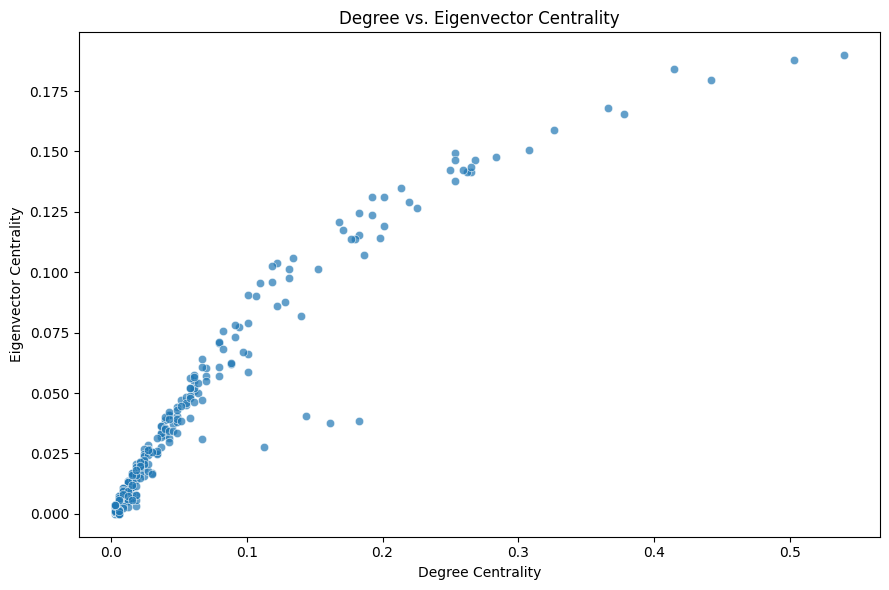

In [12]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=centrality_df,
    x="Degree_Centrality",
    y="Eigenvector_Centrality",
    alpha=0.7
)

plt.title("Degree vs. Eigenvector Centrality")
plt.xlabel("Degree Centrality")
plt.ylabel("Eigenvector Centrality")

plt.tight_layout()
plt.show()

The scatterplot shows a strong positive relationship between degree centrality and eigenvector centrality. As the number of direct connections increases, eigenvector centrality generally increases as well. The Spearman correlation coefficient of 0.957.

However, I noticed several airports that fall below the overall pattern. These airports have relatively high degree centrality but much lower eigenvector centrality than other airports with similar numbers of connections. This suggests that having many direct connections does not necessarily mean being connected to the most influential airports in the network.

I found this particularly interesting and decided to explore these differences further in the analysis.

In [13]:
centrality_df[
    ["Degree_Centrality", "Eigenvector_Centrality"]
].corr(method="spearman")

,Degree_Centrality,Eigenvector_Centrality
Degree_Centrality,1.00000,0.95674
Eigenvector_Centrality,0.95674,1.00000


In [15]:
airport_volume = (
    df.groupby("ORIGIN")
    .size()
    .reset_index(name="Total_Flights")
    .rename(columns={"ORIGIN": "Airport"})
)

airport_analysis = centrality_df.merge(
    airport_volume,
    on="Airport",
    how="left"
)

display(airport_analysis["Total_Flights"].describe())

count      329.000000
mean      1640.568389
std       3745.415765
min          9.000000
25%         62.000000
50%        272.000000
75%       1098.000000
max      25124.000000
Name: Total_Flights, dtype: float64

In [16]:
print("Airports without flight-volume data:",
      airport_analysis["Total_Flights"].isna().sum())

display(
    airport_analysis[
        ["Airport", "Total_Flights"]
    ].sort_values("Total_Flights").head(10)
)

Airports without flight-volume data: 0


,Airport,Total_Flights
36,ADK,9
317,CKB,9
323,SMX,9
319,PPG,10
304,SPI,14
325,SCE,16
302,OTH,18
320,HTS,20
318,HGR,20
296,LBE,22


To explore whether airport connectivity differs by airport size, I first calculated the total number of departing flight records for each airport.

Flight volume varies considerably across airports, ranging from 9 to 25,124 records. The median is 272, indicating that most airports have relatively low flight volumes compared with the busiest airports.

I used this information to categorize airports into three groups based on flight volume for the following analysis.

In [17]:
# Create airport size categories
airport_analysis["Airport_Size"] = pd.qcut(
    airport_analysis["Total_Flights"],
    q=3,
    labels=["Small", "Medium", "Large"]
)

# Check number of airports per category
print(airport_analysis["Airport_Size"].value_counts())

# Examine flight volume within each category
display(
    airport_analysis.groupby(
        "Airport_Size", observed=True
    )["Total_Flights"].describe()
)

Airport_Size
Small     118
Large     110
Medium    101
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Airport_Size,,,,,,,,
Small,118.0,57.042373,21.169804,9.0,53.0,60.0,62.00,93.0
Medium,101.0,312.673267,151.717112,101.0,178.0,279.0,416.00,621.0
Large,110.0,4558.509091,5408.376581,626.0,1102.0,1935.0,6045.25,25124.0


I categorized airports into three groups based on their January 2025 departing flight volume using quantiles. This resulted in 118 small, 101 medium, and 110 large airports.

These categories represent relative flight activity within the dataset rather than official airport-size classifications. The groups are not exactly equal in size because some airports have the same flight volume.

In [18]:
summary = (
    airport_analysis.groupby("Airport_Size", observed=True)
    .agg(
        Airports=("Airport", "count"),
        Mean_Degree=("Degree_Centrality", "mean"),
        Median_Degree=("Degree_Centrality", "median"),
        Mean_Eigenvector=("Eigenvector_Centrality", "mean"),
        Median_Eigenvector=("Eigenvector_Centrality", "median")
    )
)

display(summary)

,Airports,Mean_Degree,Median_Degree,Mean_Eigenvector,Median_Eigenvector
Airport_Size,,,,,
Small,118,0.005193,0.003049,0.003869,0.003719
Medium,101,0.020406,0.018293,0.016939,0.016228
Large,110,0.132511,0.091463,0.082262,0.066566


The summary statistics show that both degree and eigenvector centrality increase across airport-size categories. Large airports have substantially higher average centrality scores than medium and small airports.

I also noticed that the mean centrality is higher than the median in all three groups, particularly among large airports. This suggests that even within the same size category, a few airports are considerably more connected and influential than others.

However, since airport size was defined using flight volume, these differences are somewhat expected, especially for degree centrality.

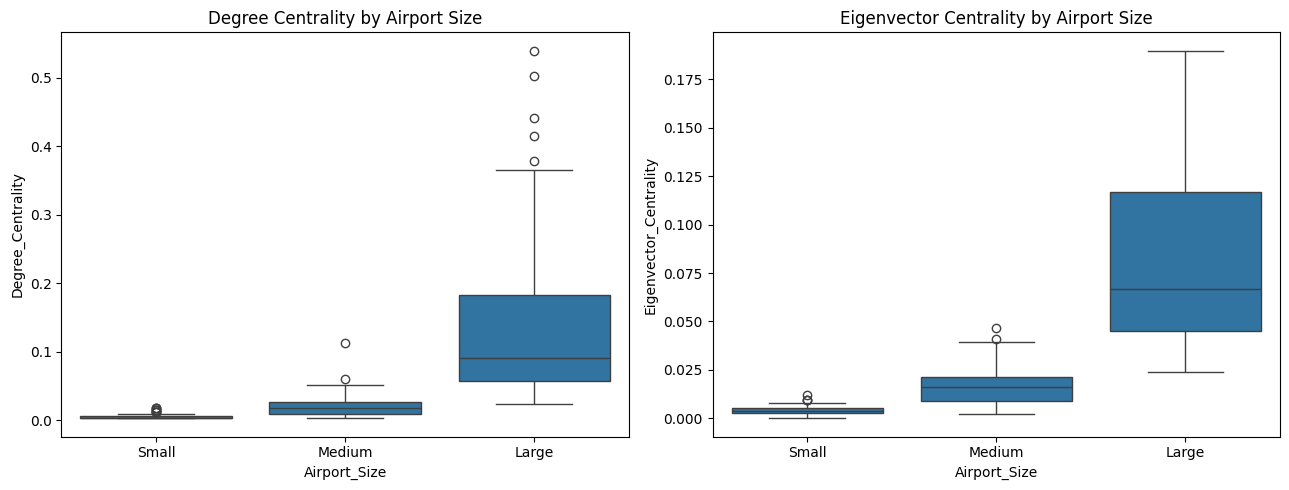

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = ["Small", "Medium", "Large"]

sns.boxplot(
    data=airport_analysis,
    x="Airport_Size",
    y="Degree_Centrality",
    order=order,
    ax=axes[0]
)

axes[0].set_title("Degree Centrality by Airport Size")

sns.boxplot(
    data=airport_analysis,
    x="Airport_Size",
    y="Eigenvector_Centrality",
    order=order,
    ax=axes[1]
)

axes[1].set_title("Eigenvector Centrality by Airport Size")

plt.tight_layout()
plt.show()

The boxplots show a clear increase in both degree and eigenvector centrality from small to large airports, consistent with the summary statistics.

What I found interesting is the greater variability among large airports. Although these airports are grouped together based on flight volume, their centrality scores differ considerably. This suggests that airports with similarly high flight activity do not necessarily have the same level of connectivity or network influence.

The degree centrality plot also shows several outliers among large airports, indicating that a few major hubs have substantially more direct connections than others in the same category.

In [20]:
from scipy.stats import kruskal

groups = ["Small", "Medium", "Large"]

# Degree centrality
degree_groups = [
    airport_analysis.loc[
        airport_analysis["Airport_Size"] == group,
        "Degree_Centrality"
    ].dropna()
    for group in groups
]

# Eigenvector centrality
eigen_groups = [
    airport_analysis.loc[
        airport_analysis["Airport_Size"] == group,
        "Eigenvector_Centrality"
    ].dropna()
    for group in groups
]

# Run tests
h_degree, p_degree = kruskal(*degree_groups)
h_eigen, p_eigen = kruskal(*eigen_groups)

print(f"Degree centrality: H = {h_degree:.3f}, p = {p_degree:.3e}")
print(f"Eigenvector centrality: H = {h_eigen:.3f}, p = {p_eigen:.3e}")

Degree centrality: H = 263.911, p = 4.925e-58
Eigenvector centrality: H = 269.785, p = 2.612e-59


Since the centrality distributions are strongly skewed, I used the nonparametric Kruskal–Wallis test to compare degree and eigenvector centrality across the three airport-size categories.

The results showed statistically significant differences for both degree centrality (H = 263.91, p < 0.001) and eigenvector centrality (H = 269.79, p < 0.001).

Although these results suggest that centrality differs across airport-size groups, the findings are somewhat expected because the categories were defined using flight volume, which is closely related to airport connectivity.

In [21]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from itertools import combinations

results = []

for measure in ["Degree_Centrality", "Eigenvector_Centrality"]:
    for group1, group2 in combinations(
        ["Small", "Medium", "Large"], 2
    ):
        x = airport_analysis.loc[
            airport_analysis["Airport_Size"] == group1, measure
        ]

        y = airport_analysis.loc[
            airport_analysis["Airport_Size"] == group2, measure
        ]

        u, p = mannwhitneyu(x, y, alternative="two-sided")

        results.append({
            "Measure": measure,
            "Comparison": f"{group1} vs {group2}",
            "U": u,
            "p_value": p
        })

pairwise = pd.DataFrame(results)

pairwise["p_adjusted"] = (
    pairwise.groupby("Measure")["p_value"]
    .transform(lambda p: multipletests(p, method="holm")[1])
)

display(pairwise)

,Measure,Comparison,U,p_value,p_adjusted
0,Degree_Centrality,Small vs Medium,1081.0,9.514514e-27,9.514514e-27
1,Degree_Centrality,Small vs Large,0.0,4.116575e-40,1.234973e-39
2,Degree_Centrality,Medium vs Large,292.5,1.426486e-32,2.852972e-32
3,Eigenvector_Centrality,Small vs Medium,740.5,5.761926e-29,5.761926e-29
4,Eigenvector_Centrality,Small vs Large,0.0,6.914613e-39,2.074384e-38
5,Eigenvector_Centrality,Medium vs Large,188.0,8.995498e-34,1.799100e-33


Following the Kruskal–Wallis tests, I performed pairwise Mann–Whitney U tests with Holm correction to identify which airport-size groups differed.

All three pairwise comparisons were statistically significant for both degree and eigenvector centrality (adjusted p < 0.001). This supports the pattern observed in the boxplots, where centrality generally increases from small to medium to large airports.

However, these findings should be interpreted cautiously because airport-size categories were defined using flight volume, which is closely related to network connectivity.

## Geographic Visualization of Airport Connectivity

To better understand the geographic structure of the network, I created an interactive map showing major airports and their direct connections. I used airport coordinates from the `airportsdata` package and Plotly for visualization.

In [22]:
import plotly.graph_objects as go
import airportsdata
import pandas as pd

In [23]:
# Load airport location data
airport_locations = airportsdata.load("IATA")

# Create coordinate lookup
coordinates = pd.DataFrame([
    {
        "Airport": code,
        "Latitude": info["lat"],
        "Longitude": info["lon"]
    }
    for code, info in airport_locations.items()
])

# Merge with our airport-level dataset
airport_map = airport_analysis.merge(
    coordinates,
    on="Airport",
    how="left"
)

print(
    "Airports missing coordinates:",
    airport_map["Latitude"].isna().sum()
)

Airports missing coordinates: 0


In [ ]:
# Top 20 airports by degree centrality
top20 = set(
    airport_map.nlargest(20, "Degree_Centrality")["Airport"]
)

# Exclude Alaska, Hawaii, and territories from this visualization
excluded_states = ["AK", "HI", "PR", "VI", "GU", "AS", "MP"]

# Get state information for each airport
airport_states = (
    pd.concat([
        df[["ORIGIN", "ORIGIN_STATE_ABR"]].rename(
            columns={"ORIGIN": "Airport",
                     "ORIGIN_STATE_ABR": "State"}
        ),
        df[["DEST", "DEST_STATE_ABR"]].rename(
            columns={"DEST": "Airport",
                     "DEST_STATE_ABR": "State"}
        )
    ])
    .drop_duplicates(subset="Airport")
)

map_nodes = airport_map.merge(
    airport_states, on="Airport", how="left"
)

map_nodes = map_nodes[
    ~map_nodes["State"].isin(excluded_states)
].dropna(subset=["Latitude", "Longitude"])

valid_airports = set(map_nodes["Airport"])
top20 = top20 & valid_airports

# Routes connecting at least one top-20 hub
hub_routes = undirected_routes[
    (
        undirected_routes["airport_1"].isin(top20) |
        undirected_routes["airport_2"].isin(top20)
    ) &
    undirected_routes["airport_1"].isin(valid_airports) &
    undirected_routes["airport_2"].isin(valid_airports)
]

In [35]:
import plotly.graph_objects as go

coords = map_nodes.set_index("Airport")[
    ["Latitude", "Longitude"]
].to_dict("index")

fig = go.Figure()

# Draw routes in one trace for better performance
edge_lons = []
edge_lats = []

for _, route in hub_routes.iterrows():
    a, b = route["airport_1"], route["airport_2"]

    edge_lons.extend([
        coords[a]["Longitude"],
        coords[b]["Longitude"],
        None
    ])
    edge_lats.extend([
        coords[a]["Latitude"],
        coords[b]["Latitude"],
        None
    ])

fig.add_trace(go.Scattergeo(
    lon=edge_lons,
    lat=edge_lats,
    mode="lines",
    line=dict(width=0.4, color="rgba(100,100,100,0.15)"),
    hoverinfo="skip",
    showlegend=False
))

# Show all airport nodes
fig.add_trace(go.Scattergeo(
    lon=map_nodes["Longitude"],
    lat=map_nodes["Latitude"],
    mode="markers",
    marker=dict(size=3, color="lightgray"),
    name="Other Airports",
    text=map_nodes["Airport"]
))

# Highlight the top 20 hubs
hub_nodes = map_nodes[
    map_nodes["Airport"].isin(top20)
]

fig.add_trace(go.Scattergeo(
    lon=hub_nodes["Longitude"],
    lat=hub_nodes["Latitude"],
    mode="markers+text",
    text=hub_nodes["Airport"],
    textposition="top center",
    marker=dict(
        size=8 + hub_nodes["Degree_Centrality"] * 40,
        color="royalblue",
        line=dict(color="white", width=1)
    ),
    name="Top 20 Hubs",
    customdata=hub_nodes[
        ["Degree", "Eigenvector_Centrality"]
    ].to_numpy(),
    hovertemplate=(
        "<b>%{text}</b>"
        "<br>Direct connections: %{customdata[0]}"
        "<br>Eigenvector centrality: %{customdata[1]:.3f}"
        "<extra></extra>"
    )
))

fig.update_geos(
    scope="usa",
    projection_type="albers usa",
    lonaxis_range=[-126, -66],
    lataxis_range=[24, 50],
    showland=True,
    landcolor="#f7f7f7",
    showsubunits=True,
    subunitcolor="#dddddd"
)

fig.update_layout(
    title="Airport Network Connectivity: Top 20 Hubs (January 2025)",
    height=700,
    margin=dict(l=0, r=0, t=60, b=0)
)

fig.show()

The map shows the geographic distribution of the 20 most connected airports and their direct routes to other airports in the contiguous United States. Larger blue markers represent airports with higher degree centrality.

Major hubs such as DFW, DEN, ORD, and ATL have connections across different regions of the country, highlighting their central role in the network.

Although the map only displays the contiguous United States for readability, the centrality measures were calculated using the complete network of 329 airports.

## Exploratory Analysis: Geographic Differences in Centrality

In [36]:
# Compare selected airports with different connectivity patterns
selected_airports = [
    "JNU", "KTN", "WRG", "PSG",
    "SFB", "PIE", "PGD", "AZA",
    "DFW", "DEN"
]

comparison = airport_analysis[
    airport_analysis["Airport"].isin(selected_airports)
][
    ["Airport", "Degree", "Degree_Centrality",
     "Eigenvector_Centrality"]
].copy()

# Average number of connections among neighboring airports
neighbor_degree = nx.average_neighbor_degree(G)

comparison["Avg_Neighbor_Degree"] = (
    comparison["Airport"].map(neighbor_degree)
)

display(
    comparison.sort_values("Degree", ascending=False)
    .round(4)
)

,Airport,Degree,Degree_Centrality,Eigenvector_Centrality,Avg_Neighbor_Degree
6,DFW,177,0.5396,0.1898,26.5480
13,DEN,165,0.5030,0.1878,28.5636
4,SFB,60,0.1829,0.0386,14.0667
3,PIE,53,0.1616,0.0375,15.6226
2,PGD,47,0.1433,0.0405,20.4681
150,AZA,37,0.1128,0.0275,18.0811
46,JNU,6,0.0183,0.0034,19.1667
293,KTN,4,0.0122,0.0028,23.2500
321,PSG,2,0.0061,0.0001,4.0000
322,WRG,2,0.0061,0.0001,3.0000


In [37]:
# Compare airports with similar numbers of connections
similar_degree = centrality_df[
    centrality_df["Degree"].between(40, 70)
].copy()

display(
    similar_degree[
        ["Airport", "Degree",
         "Degree_Centrality", "Eigenvector_Centrality"]
    ].sort_values("Eigenvector_Centrality")
    .round(4)
)

,Airport,Degree,Degree_Centrality,Eigenvector_Centrality
3,PIE,53,0.1616,0.0375
4,SFB,60,0.1829,0.0386
2,PGD,47,0.1433,0.0405
132,SRQ,46,0.1402,0.0817
130,SMF,40,0.1220,0.0860
34,RSW,42,0.1280,0.0879
64,CVG,43,0.1311,0.0975
112,PIT,43,0.1311,0.1014
110,PDX,50,0.1524,0.1015
102,MSY,40,0.1220,0.1037


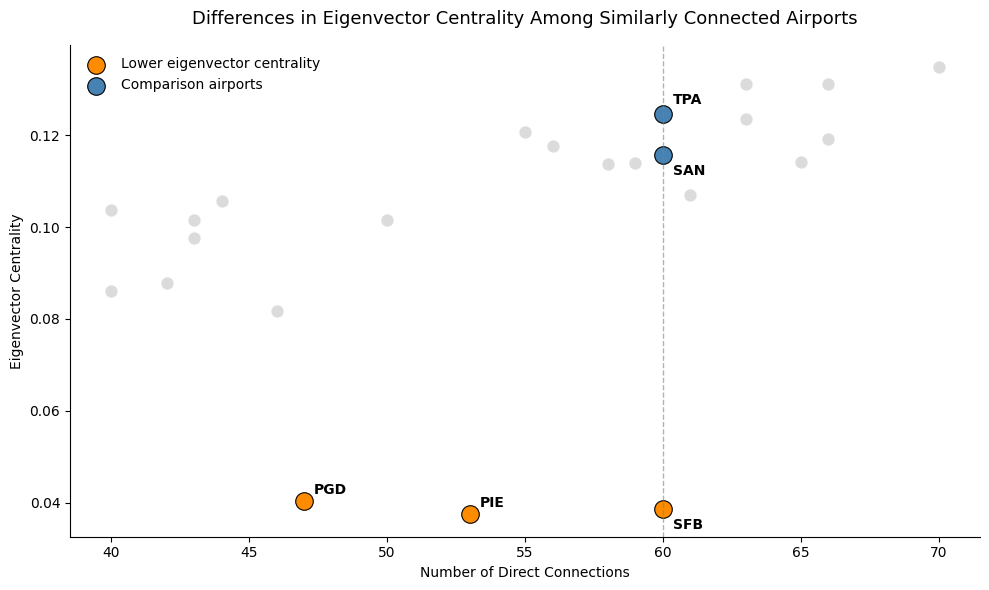

In [39]:
# Airports with 40–70 direct connections
similar_degree = centrality_df[
    centrality_df["Degree"].between(40, 70)
].copy()

# Airports of interest
low_eigen = ["SFB", "PIE", "PGD"]
comparison_airports = ["SAN", "TPA"]

fig, ax = plt.subplots(figsize=(10, 6))

# Plot all airports in gray
sns.scatterplot(
    data=similar_degree,
    x="Degree",
    y="Eigenvector_Centrality",
    color="lightgray",
    s=90,
    alpha=0.8,
    ax=ax
)

# Highlight airports with relatively low eigenvector centrality
low_data = similar_degree[
    similar_degree["Airport"].isin(low_eigen)
]

sns.scatterplot(
    data=low_data,
    x="Degree",
    y="Eigenvector_Centrality",
    color="darkorange",
    s=160,
    edgecolor="black",
    linewidth=0.8,
    ax=ax,
    label="Lower eigenvector centrality"
)

# Highlight comparison airports
comparison_data = similar_degree[
    similar_degree["Airport"].isin(comparison_airports)
]

sns.scatterplot(
    data=comparison_data,
    x="Degree",
    y="Eigenvector_Centrality",
    color="steelblue",
    s=160,
    edgecolor="black",
    linewidth=0.8,
    ax=ax,
    label="Comparison airports"
)

# Highlight the shared degree of SFB, SAN, and TPA
ax.axvline(
    x=60,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

# Add labels with small offsets
label_offsets = {
    "SFB": (7, -14),
    "PIE": (7, 5),
    "PGD": (7, 5),
    "SAN": (7, -14),
    "TPA": (7, 7)
}

for _, row in similar_degree[
    similar_degree["Airport"].isin(low_eigen + comparison_airports)
].iterrows():

    ax.annotate(
        row["Airport"],
        (row["Degree"], row["Eigenvector_Centrality"]),
        xytext=label_offsets[row["Airport"]],
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Differences in Eigenvector Centrality Among Similarly Connected Airports",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Number of Direct Connections")
ax.set_ylabel("Eigenvector Centrality")

ax.legend(frameon=False, loc="upper left")

sns.despine()
plt.tight_layout()
plt.show()

To explore why degree and eigenvector centrality do not always follow the same pattern, I compared airports with 40–70 direct connections.

Three airports—PGD, PIE, and SFB—stood out with substantially lower eigenvector centrality than other airports with similar degrees. For example, SFB, SAN, and TPA each have 60 direct connections, but their eigenvector centrality scores are approximately 0.039, 0.116, and 0.125, respectively.

This was one of the more interesting findings of the analysis because it demonstrates that the number of direct connections alone does not fully describe an airport's position within the network. Eigenvector centrality also accounts for the importance of neighboring airports, which may help explain these differences.

### Conclusion

Initially, I wanted to understand whether airport connectivity differed by airport size. After categorizing airports based on flight volume, I found statistically significant differences in both centrality measures across small, medium, and large airports. However, as I worked through the analysis, I realized that this finding was somewhat expected, since flight volume and the number of direct connections are closely related.

What I found more interesting was that airports with similar numbers of connections did not necessarily have similar eigenvector centrality scores. For example, SFB, SAN, and TPA each had 60 direct connections, but their eigenvector centrality values differed considerably. This suggests that an airport's importance within the network depends not only on how many connections it has, but also on how influential its neighboring airports are.

There are several limitations to this analysis. The data cover only January 2025, so seasonal differences in flight activity are not captured. Additionally, the network is undirected and unweighted, meaning that flight frequency and direction are not considered. The airport-size categories were also defined using flight volume from the same dataset, and the statistical comparisons should be interpreted as exploratory.

Overall, this project helped me better understand how different centrality measures capture different aspects of network structure. A possible next step would be to explore whether airport centrality is associated with flight delays or cancellations, which was part of my original interest in this dataset.

